In [37]:
# pip install tavily

In [38]:
from  langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from langgraph.prebuilt import ToolNode
import operator
from tavily import TavilyClient
from langchain_core.documents import Document
import os
load_dotenv()

True

In [ ]:
from langchain_core.tools import tool
import requests


@tool
def get_weather(location:str) -> str:
    """Get current weather for a location.
    
    Use for queries about weather, temperature, or conditions in any city.
    Examples: "weather in Paris", "temperature in Tokyo", "is it raining in London"
    
    Args:
        location: City name (e.g., "New York", "London", "Tokyo")
        
    Returns:
        Current weather information including temperature and conditions.
    """

    url = f"https://wttr.in/{location}?format=j1"
    response = requests.get(url, timeout=10)

    response.raise_for_status()
    data = response.json()

    return data



@tool
def web_search(query:str, max_results:int = 3):
    """
    Search the web for relevant information.
    Adjust max_results (default 3) to retrieve more or fewer results.
    """
    client = TavilyClient(api_key=os.getenv("TVLY_API_KEY"))
    response = client.search(query, max_results=max_results)
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return content



# create python function to talk your db --> tool --> register it 




In [40]:
all_tools = [get_weather,web_search]

llm = ChatOpenAI(model="gpt-4o-mini")

In [41]:
class AgentState(TypedDict):
    messages: Annotated[list, operator.add]

In [42]:
def agent_node(state: AgentState):
    llm_with_tools = llm.bind_tools(all_tools)
    messages = state['messages']
    response = llm_with_tools.invoke(messages)

    if hasattr(response, 'tool_calls') and response.tool_calls:
        for tc in response.tool_calls:
            print(f"[AGENT] called Tool {tc.get('name', '?')} with args {tc.get('args', '?')}")
    else:
        print(f"[AGENT] Responding...")


    return {'messages': [response]}

In [43]:
def should_continue(state: AgentState):
    last = state['messages'][-1]
    
    if hasattr(last, 'tool_calls') and last.tool_calls:
        return "tools"
    else:
        return END

In [44]:
def create_agent():
    builder = StateGraph(AgentState)
    builder.add_node("agent", agent_node)
    builder.add_node("tools", ToolNode(all_tools))
    builder.add_edge(START, "agent")
    builder.add_conditional_edges("agent", should_continue, ["tools", END])
    builder.add_edge("tools", "agent")
    graph = builder.compile()
    return graph

In [45]:
agent = create_agent()


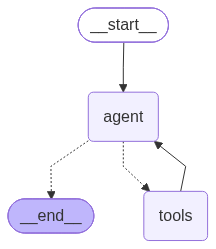

In [46]:
agent

In [47]:
query = "What is the current weather in Mumbai?"

result = agent.invoke({'messages': [HumanMessage(query)]})


[AGENT] called Tool get_weather with args {'location': 'Mumbai'}
[AGENT] Responding...


In [48]:
result

{'messages': [HumanMessage(content='What is the current weather in Mumbai?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 165, 'total_tokens': 179, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c8a50cb3d4', 'id': 'chatcmpl-Eofd0Se4EV7hhHGYe11A4kzB2Hgmj', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a21ac0-12e2-7e31-82e0-6087e51d25c6-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Mumbai'}, 'id': 'call_7viBv0WWiZVF5gP0aWgOyZmQ', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 165, 'outp

In [54]:
query = "what is current temp in Mumbai and tell me top 5 news for today"

result = agent.invoke({'messages': [HumanMessage(query)]})


[AGENT] called Tool get_weather with args {'location': 'Mumbai'}
[AGENT] called Tool web_search with args {'query': 'top news in Mumbai', 'max_results': 5}
[AGENT] Responding...


In [55]:
print(result['messages'][-1].content)

### Current Weather in Mumbai
- **Temperature:** 23°C (Feels like 25°C)
- **Conditions:** Clear 
- **Humidity:** 68%
- **Wind Speed:** 5 km/h from the NE
- **Pressure:** 1015 hPa
- **Visibility:** 10 km

![Weather Icon](https://cdn.worldweatheronline.com/images/wsymbols01_png_64/wsymbol_0008_clear_sky_night.png)

### Top 5 News in Mumbai
1. **Grenade Attack Threat:** Mumbai received a chilling email warning of grenade attacks targeting the Mayor's Office and metro stations, reportedly linked to historical Khalistani violence. Officials are pursuing legal action after finding no immediate threat.
   
2. **Stabbing Incident:** A 53-year-old man was stabbed in a local train, prompting an arrest of the accused. This incident raises concerns about safety in public transport.

3. **Earthshot Prize Awards:** The Earthshot Prize 2026 was recently held in Mumbai, focusing on partnerships and investments for scaling environmental solutions.

4. **Demolition Drive in Andheri:** The Brihanmumbai M